# Preparation & Cleaning of data


From the raw trimmed World Values Survey Wave 7 data, we used four material hardship questions (Q51, Q53-Q55) to operationalize economic insecurity by measuring how frequently respondents went without material necessities. Missing or invalid responses are removed. The data is then split according to the seven Southeast Asian countries in the data. We also reverse coded the hardship scale so higher values represent greater material deprivation. Lastly, we clean the data from five economic norm violation questions (Q177-Q181), and the fourteen personal norm questions (Q182-Q195).

In [2]:
# loading python libraries 
import pandas as pd
import numpy as np

In [3]:
#Load raw dataset 
df_raw = pd.read_csv('../data/raw/WVS_Survey_Trimmed_2.csv')

In [4]:

# selecting core required variables 
need = ['B_COUNTRY_ALPHA', 'W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']
df = df_raw[need].copy()

# make sure the survey items and weight are numeric
for c in ['W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# WVS missing codes (all negative) -> NaN
items = {'Q51': 'food', 'Q53': 'medicine', 'Q54': 'cash_income', 'Q55': 'shelter'}
for q in items:
    df[q] = df[q].where(df[q] > 0)

# recoding country codes into country names 
country_map = {
    'MMR': 'Myanmar', 'IDN': 'Indonesia', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'VNM': 'Vietnam', 'THA': 'Thailand'
}
sea = df[df['B_COUNTRY_ALPHA'].isin(country_map)].copy()

# 1=Often, 2=Sometimes, 3=Rarely, 4=Never -> 4,3,2,1
for q in items:
    sea[q] = 5 - sea[q]

In [5]:
#check that code was excuted correctly and see the frequency of responses accorss countires
print(sea[list(items)].apply(lambda s: s.value_counts(dropna=False).sort_index()))

      Q51   Q53   Q54   Q55
1.0  7690  6808  6182  9611
2.0  1703  2380  2211  1035
3.0  1640  1745  2415   633
4.0   585   677   806   332
NaN     7    15    11    14


In [6]:
# Q177-181: justifiability of economic norm violations (1 = Never justifiable, 10 = Always justifiable)
questions = {
    'Q177': 'benefits',         # Claiming government benefits you're not entitled to
    'Q178': 'fare_avoidance',   # Avoiding a fare on public transport
    'Q179': 'stealing',         # Stealing property
    'Q180': 'tax_cheating',     # Cheating on taxes if you have a chance
    'Q181': 'bribery'           # Someone accepting a bribe in the course of their duties
}

In [7]:
#Filtering out missing or 'don't know' responses, keeping only valid answers. Then we calculate the weighted average of the responses, using each respondent's survey weight as provided in the dataset (W_WEIGHT) to correct for sampling design.
def weighted_mean(group, col):
    valid = group[group[col] > 0]   # drop negative missing/don't-know codes
    return np.average(valid[col], weights=valid['W_WEIGHT'])

In [8]:
# Use the Q182-Q195 columns only
q_cols = [f"Q{i}" for i in range(182, 196)]

In [9]:
# SEA respondents only; Q182-Q195 are not on `df`/`sea` (those frames keep the hardship items)
country_col = 'B_COUNTRY_ALPHA'
df_sea = df_raw.loc[sea.index, [country_col] + q_cols].copy()

# change the variable into numeric and remove missing code
df_sea[q_cols] = df_sea[q_cols].apply(pd.to_numeric, errors="coerce")
df_sea[q_cols] = df_sea[q_cols].where(df_sea[q_cols] > 0)

# Rebased PV & EV scores OLS for pooled 7 countries

Since the scales are different for the questions, we rescaled the questions to a common multiple of 20.

In [10]:
# Start from 'sea' (already has hardship recoded, SEA only)
df_individual = sea.copy()

# Add ethics items (Q177-Q181) from df_raw
ethics_cols = ['Q177', 'Q178', 'Q179', 'Q180', 'Q181']
for col in ethics_cols:
    raw_col = pd.to_numeric(df_raw.loc[df_individual.index, col], errors='coerce')
    df_individual[col] = raw_col.where(raw_col > 0)

# Create individual indices, all rebased to 20
hardship_items = ['Q51', 'Q53', 'Q54', 'Q55']
df_individual['deprivation_mean'] = df_individual[hardship_items].mean(axis=1, skipna=True)   # 1-4
df_individual['deprivation_rebased20'] = df_individual['deprivation_mean'] * 5               # 5-20

EV_raw = df_individual[ethics_cols].mean(axis=1, skipna=True)                                 # 1-10
df_individual['EV_rebased20'] = EV_raw * 2                                                    # 2-20

# Drop missing values
df_model = df_individual.dropna(subset=['deprivation_rebased20', 'EV_rebased20', 'W_WEIGHT'])



# OLS Output - Individual Countries

We create bivariate baseline regression models for each of the seven Southeast Asian countries, for both economic and personal norm violations. We then create a comparison table that consolidates the coefficients, standard errors, p-values, and statistical significance flags into a table for comparison.

In [ ]:
# OLS tables for economic insecurity by country (rebased to 20)
import statsmodels.formula.api as smf

results_by_country = {}

print("="*70)
print("INDIVIDUAL-LEVEL OLS: Deprivation -> Economic Norm Violations (both rebased to 20)")
print("="*70)

for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()

    if len(df_country) < 100:
        print(f"\n{country}: N={len(df_country)} (too small, skipping)")
        continue

    model = smf.wls(
        "EV_rebased20 ~ deprivation_rebased20",
        data=df_country, weights=df_country['W_WEIGHT']).fit()

    results_by_country[country] = model

    print(f"\n{'='*70}")
    print(f"{country} (N={len(df_country)})")
    print('='*70)
    print(model.summary())

#save the OLS tables in github folder 
with open('../output/tables/country_regressions_economic.txt', 'w') as f:
    for country, model in results_by_country.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_economic.txt")

INDIVIDUAL-LEVEL OLS: Deprivation -> Economic Norm Violations (both rebased to 20)

IDN (N=3199)
                            WLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.039
Model:                            WLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     131.2
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           8.27e-30
Time:                        16:51:28   Log-Likelihood:                -8720.4
No. Observations:                3199   AIC:                         1.744e+04
Df Residuals:                    3197   BIC:                         1.746e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------


MYS (N=1313)
                            WLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.039
Model:                            WLS   Adj. R-squared:                  0.038
Method:                 Least Squares   F-statistic:                     53.09
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.47e-13
Time:                        16:51:28   Log-Likelihood:                -3733.4
No. Observations:                1313   AIC:                             7471.
Df Residuals:                    1311   BIC:                             7481.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept       

In [12]:
q_cols_personal = [f"Q{i}" for i in range(182, 196)]

# focus on Q182-195 columns from df_raw, matched by respondent
df_model = df_model.join(df_raw.loc[df_model.index, q_cols_personal])

# clean: change to numeric and drop missing codes
df_model[q_cols_personal] = df_model[q_cols_personal].apply(pd.to_numeric, errors='coerce')
df_model[q_cols_personal] = df_model[q_cols_personal].where(df_model[q_cols_personal] > 0)

# average across the 14 items per respondent (1-10), then rebase to 20 (2-20)
df_model['PV_mean'] = df_model[q_cols_personal].mean(axis=1)
df_model['PV_rebased20'] = df_model['PV_mean'] * 2

print(df_model[['PV_rebased20']].describe())

       PV_rebased20
count  11599.000000
mean       5.763104
std        3.432116
min        2.000000
25%        3.142857
50%        4.714286
75%        7.714286
max       20.000000


In [13]:
# OLS tables for personal values by country (rebased to 20)

results_by_country_personal = {}

print("="*70)
print("INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)")
print("="*70)


for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()
    if len(df_country) < 100:
        print(f"\n {country}: N={len(df_country)} (too small, skipping)")
        continue
    model = smf.wls("PV_rebased20 ~ deprivation_rebased20", data=df_country, weights=df_country['W_WEIGHT']).fit()

    results_by_country_personal[country] = model
    print(f"\n{country} (N={len(df_country)})")
    print(model.summary())

#save the OLS tables in github folder 
with open('../output/tables/country_regressions_personal.txt', 'w') as f:
    for country, model in results_by_country_personal.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_personal.txt")

INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)

IDN (N=3199)
                            WLS Regression Results                            
Dep. Variable:           PV_rebased20   R-squared:                       0.007
Model:                            WLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     24.15
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           9.38e-07
Time:                        16:51:29   Log-Likelihood:                -7847.7
No. Observations:                3198   AIC:                         1.570e+04
Df Residuals:                    3196   BIC:                         1.571e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [14]:
# Comparison of OLS (both DVs and the IV rebased to 20, so betas are directly comparable)
term = 'deprivation_rebased20'
comparison_clean = pd.DataFrame({
    country: {
        'Economic Norms: β (coefficient)': results_by_country[country].params[term],
        'Economic Norms: p-value': results_by_country[country].pvalues[term],
        'Economic Norms: Significant?': 'Yes' if results_by_country[country].pvalues[term] < 0.05 else 'No',
        'Personal Norms: β (coefficient)': results_by_country_personal[country].params[term],
        'Personal Norms: p-value': results_by_country_personal[country].pvalues[term],
        'Personal Norms: Significant?': 'Yes' if results_by_country_personal[country].pvalues[term] < 0.05 else 'No',
    }
    for country in results_by_country
}).T

num_cols = ['Economic Norms: β (coefficient)', 'Economic Norms: p-value',
            'Personal Norms: β (coefficient)', 'Personal Norms: p-value']
comparison_clean[num_cols] = comparison_clean[num_cols].astype(float).round(4)

print(comparison_clean)
comparison_clean.to_csv('../output/tables/individual_level_comparison.csv')

     Economic Norms: β (coefficient)  Economic Norms: p-value  \
IDN                           0.1895                   0.0000   
MMR                           0.1193                   0.0000   
MYS                           0.2526                   0.0000   
PHL                           0.0841                   0.0286   
SGP                           0.2675                   0.0000   
THA                           0.1549                   0.0000   
VNM                           0.0282                   0.5266   

    Economic Norms: Significant?  Personal Norms: β (coefficient)  \
IDN                          Yes                           0.0619   
MMR                          Yes                           0.0411   
MYS                          Yes                           0.2139   
PHL                          Yes                           0.0399   
SGP                          Yes                           0.0354   
THA                          Yes                           0.0074

# OLS in graph form

We then translate the regression models for each country into linear graphs for visualization.

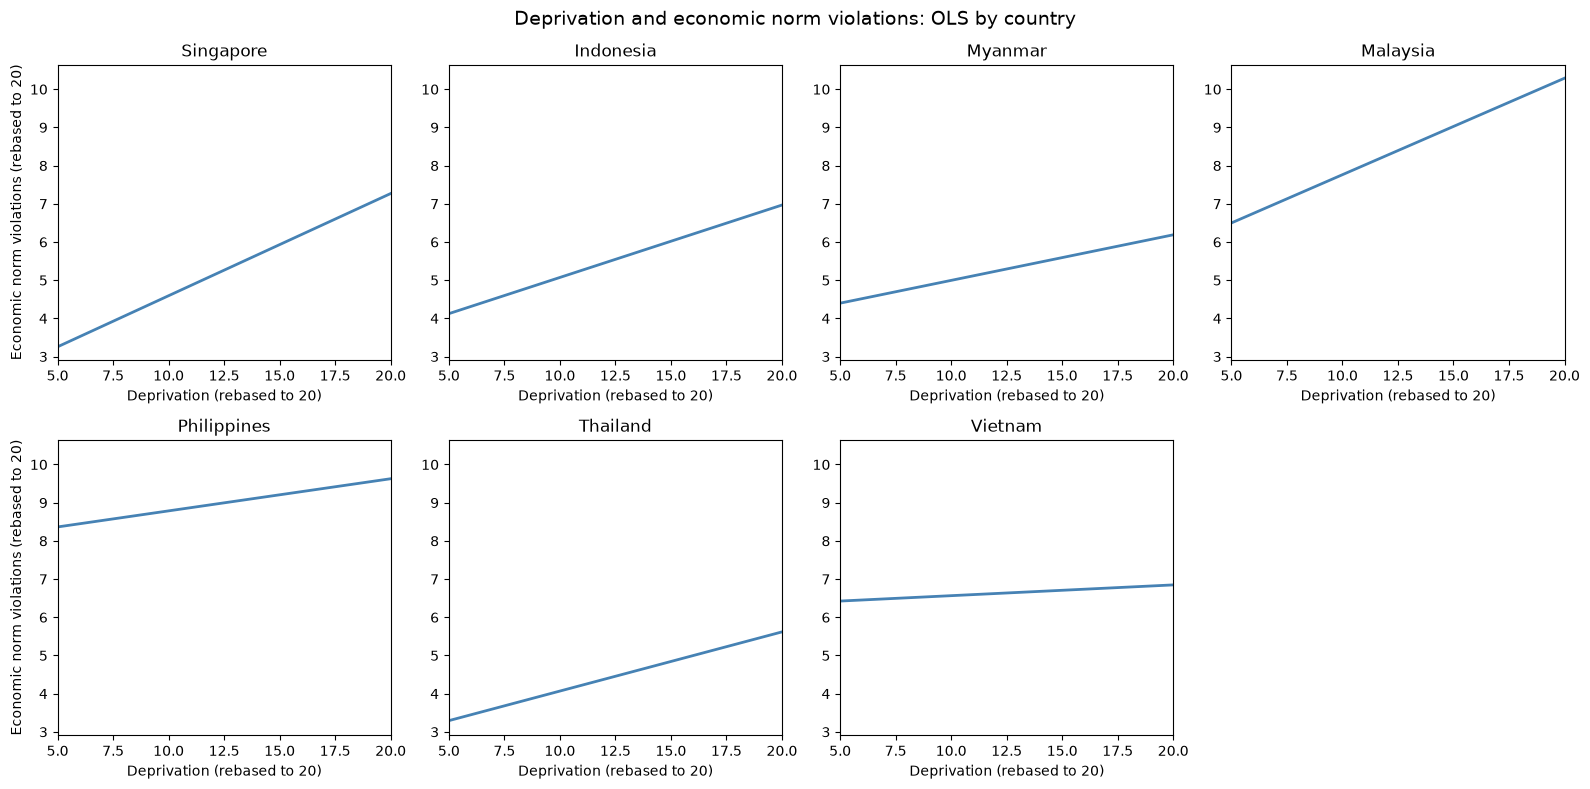

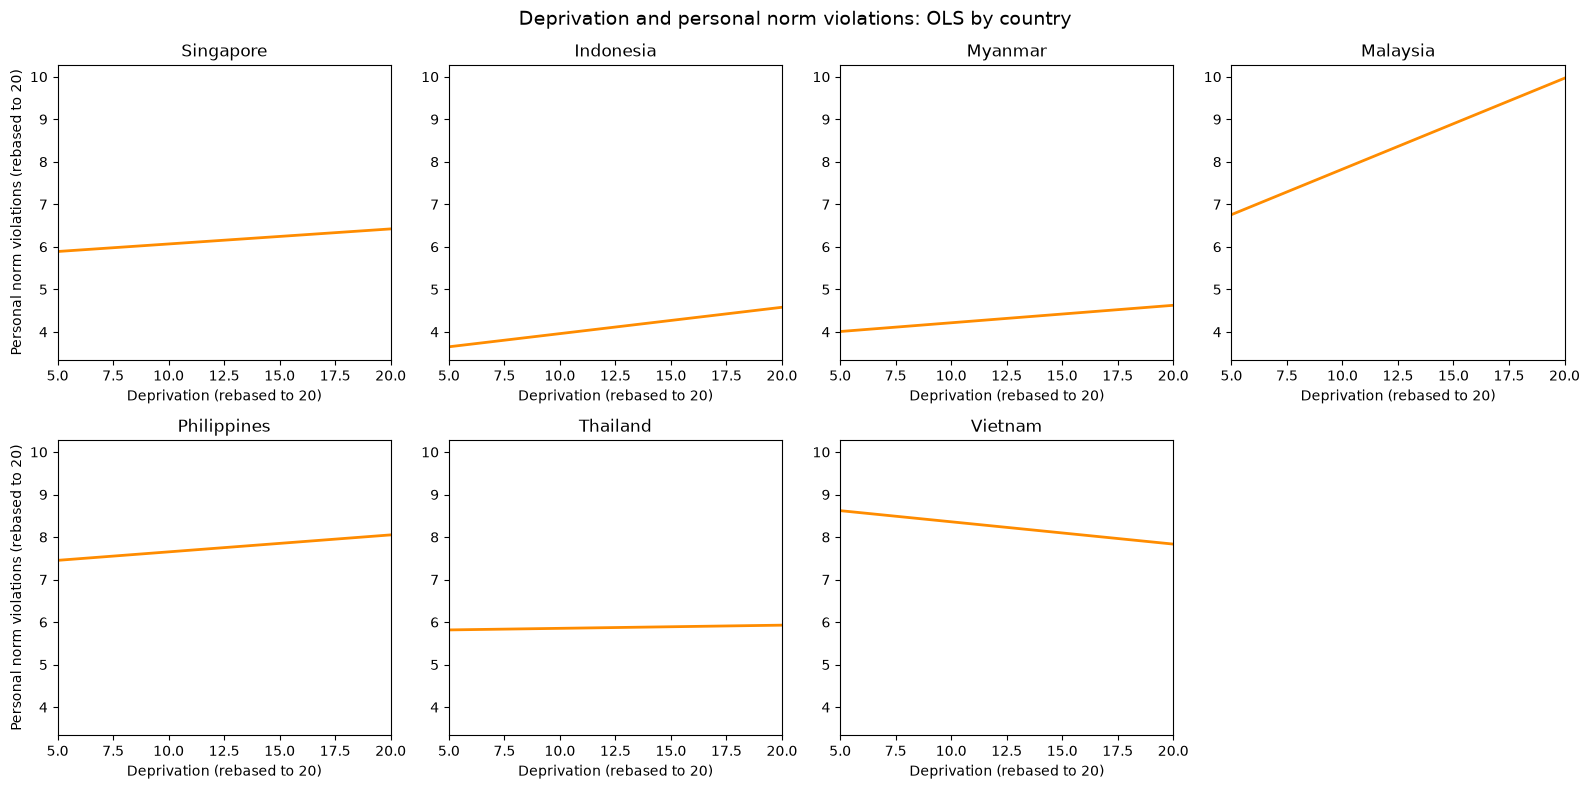

In [ ]:
# Plot the beta coefficients graph forms by country and by economic and personal norms 
import matplotlib.pyplot as plt

country_names = {
    'IDN': 'Indonesia', 'MMR': 'Myanmar', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'THA': 'Thailand', 'VNM': 'Vietnam'
}
order = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']

def plot_country_regressions(results, y_label, color, title, filename):
    x = pd.DataFrame({'deprivation_rebased20': np.linspace(5, 20, 50)})
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
    axes = axes.ravel()
    for ax, c in zip(axes, order):
        ax.plot(x['deprivation_rebased20'], results[c].predict(x), color=color, linewidth=2)
        ax.set_title(country_names[c])
        ax.set_xlim(5, 20)
        ax.set_xlabel('Deprivation (rebased to 20)')
    axes[-1].axis('off')   # 7 countries, 8 panels
    axes[0].set_ylabel(y_label)
    axes[4].set_ylabel(y_label)
    for ax in axes[:7]:
        ax.tick_params(labelleft=True)   # show y numbers on every panel
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f'../output/figures/{filename}', dpi=200, bbox_inches='tight')
    plt.show()

plot_country_regressions(results_by_country, 'Economic norm violations (rebased to 20)', 'steelblue',
                         'Deprivation and economic norm violations: OLS by country',
                         'country_regressions_economic.png')

plot_country_regressions(results_by_country_personal, 'Personal norm violations (rebased to 20)', 'darkorange',
                         'Deprivation and personal norm violations: OLS by country',
                         'country_regressions_personal.png')

# Pooled OLS - All 7 Countries 


We conducted a pooled OLS model to evaluate the overarching relationship across Southeast Asia as a whole; to check how material deprivation affects economic and personal norm violations overall.

In [ ]:
model_econ_pooled_simple_rebased = smf.wls(
    "EV_rebased20 ~ deprivation_rebased20",
    data=df_model, weights=df_model['W_WEIGHT']).fit()
print("=== Economic Norms (Pooled, Rebased 0-20) ===")
print(model_econ_pooled_simple_rebased.summary())

model_pers_pooled_simple_rebased = smf.wls(
    "PV_rebased20 ~ deprivation_rebased20",
    data=df_model, weights=df_model['W_WEIGHT']).fit()
print("\n=== Personal Norms (Pooled, Rebased 0-20) ===")
print(model_pers_pooled_simple_rebased.summary())

=== Economic Norms (Pooled, Rebased 0-20) ===
                            WLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.035
Model:                            WLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     421.5
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           4.90e-92
Time:                        16:51:37   Log-Likelihood:                -31778.
No. Observations:               11601   AIC:                         6.356e+04
Df Residuals:                   11599   BIC:                         6.357e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

# Comparison Graph 

We construct a grouped bar chart to compare the economic slope against the personal slope for each of the seven countries.

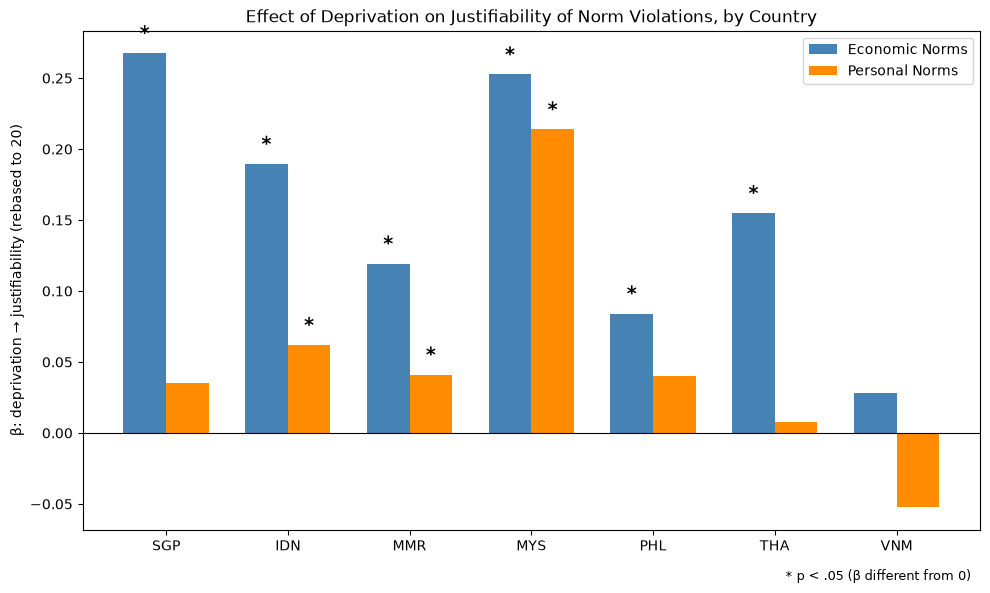

In [ ]:
# Bar chart of each country's own beta  

import matplotlib.pyplot as plt

countries = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']
term = 'deprivation_rebased20'


def get_stats(results):
    b = np.array([results[c].params[term] for c in countries])
    p = np.array([results[c].pvalues[term] for c in countries])
    return b, p


econ_b, econ_p = get_stats(results_by_country)
pers_b, pers_p = get_stats(results_by_country_personal)

x = np.arange(len(countries))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, econ_b, width, label='Economic Norms', color='steelblue')
bars2 = ax.bar(x + width/2, pers_b, width, label='Personal Norms', color='darkorange')


# * = beta significantly different from zero (p < .05)
def star(bars, b, p):
    for i, bar in enumerate(bars):
        if p[i] < 0.05:
            y = b[i] + 0.01 if b[i] >= 0 else b[i] - 0.02
            ax.text(bar.get_x() + bar.get_width() / 2, y, '*',
                    ha='center', fontsize=14, fontweight='bold')

star(bars1, econ_b, econ_p)
star(bars2, pers_b, pers_p)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(countries)
ax.set_ylabel('β: deprivation → justifiability (rebased to 20)')
ax.set_title('Effect of Deprivation on Justifiability of Norm Violations, by Country')
ax.legend()
ax.text(0.99, -0.1, '* p < .05 (β different from 0)',
        transform=ax.transAxes, ha='right', fontsize=9)
plt.tight_layout()

plt.savefig('../output/figures/country_betas_by_norm_type.png', dpi=200, bbox_inches='tight')
plt.show()

# Control variables
 

We now clean and rescale the demographic and control variables. Income, social class, age, and education attainment are all rescaled linearly to a maximum value of twenty. Religiosity is reverse coded and rescaled to twenty, while gender is coded as a binary variable. We also create a gap variable, economic violations minus personal violations, to help us test our research question directly. 

In [18]:
df_ctrl = df_model.copy()
raw = df_raw.loc[df_ctrl.index]
num = lambda col: pd.to_numeric(raw[col], errors='coerce')

In [19]:
# Income control variable (rebased to 20)
df_ctrl['income'] = num('Q288').where(lambda s: s > 0) * 2

In [20]:
# Subjective class conrol variable (rebased to 20)
df_ctrl['subj_class'] = (6 - num('Q287').where(lambda s: s > 0)) * 4

In [21]:
# Religiosity control variable (rebased to 20)
rel_items = ['I_RELIGIMP', 'I_RELIGBEL', 'I_RELIGPRAC']
for c in rel_items:
    df_ctrl[c] = num(c).where(lambda s: s >= 0)
df_ctrl['religiosity'] = (1 - df_ctrl[rel_items].mean(axis=1, skipna=True)) * 20

In [ ]:
# age control variable (rebased to 20)
age = num('Q262').where(lambda s: s > 0)
df_ctrl['age'] = age * 20 / age.max()

In [23]:
# Education control variable (rebased to 20)
df_ctrl['education'] = num('Q275').where(lambda s: s >= 0) * 2.5

In [24]:
# Gender control variable, it create a new female column (1=female, 0=male)
sex = num('Q260').where(lambda s: s > 0)
df_ctrl['female'] = (sex == 2).astype(float).where(sex.notna())

In [ ]:
# beta of economic minus the beta personal norms to see if there is a difference in relation to different variables
df_ctrl['gap_EV_PV'] = df_ctrl['EV_rebased20'] - df_ctrl['PV_rebased20']
df_ctrl['country'] = df_ctrl['B_COUNTRY_ALPHA'].astype(str)

# create models with different control varibles 
control_sets = {
    'M0': [], # no control variables 
    'M1': ['income', 'subj_class'], # control for income and class
    'M2': ['income', 'subj_class', 'religiosity'], # control for income and class and religion 
    'M3': ['income', 'subj_class', 'religiosity', 'age', 'female', 'education'], # control for income and class and religion, age, gender, and education
}
FULL = list(control_sets)[-1]
all_controls = control_sets[FULL]

print(df_ctrl[['deprivation_rebased20', 'EV_rebased20', 'PV_rebased20', 'income', 'subj_class', 'religiosity', 'age', 'education', 'female']].agg(['min', 'max']).round(1).to_string())

# cleaning of the data (remove missing values), put the number of missing values removed in a table, while showing the before and after sample size of M3
analysis = df_ctrl.dropna(subset=['deprivation_rebased20', 'EV_rebased20', 'PV_rebased20', 'W_WEIGHT'] + all_controls).copy()
n_table = pd.DataFrame({'before': df_ctrl['country'].value_counts(), 'after': analysis['country'].value_counts()})
n_table['dropped'] = n_table['before'] - n_table['after']
print(f'\nFull model: {FULL}. Respondents kept: {len(analysis)} of {len(df_ctrl)}')
print(n_table.sort_index().to_string())

     deprivation_rebased20  EV_rebased20  PV_rebased20  income  subj_class  religiosity   age  education  female
min                    5.0           2.0           2.0     2.0         4.0          0.0   3.5        0.0     0.0
max                   20.0          20.0          20.0    20.0        20.0         20.0  20.0       20.0     1.0

Full model: M3. Respondents kept: 11419 of 11601
         before  after  dropped
country                        
IDN        3199   3127       72
MMR        1200   1198        2
MYS        1313   1313        0
PHL        1200   1199        1
SGP        2004   1925       79
THA        1485   1457       28
VNM        1200   1200        0


# OLS with controls 

We use four (M0, M1, M2, M3) models, ranging from an unadjusted baseline to the fully adjusted model that accounts for all the variables simultaneously.

In [26]:
DVS = {'Economic': 'EV_rebased20', 'Personal': 'PV_rebased20', 'Gap': 'gap_EV_PV'}
IV = 'deprivation_rebased20'
ALL = 'Pooled'
# Effect (sum-to-zero) coding: countries are compared with the 7-country average, no reference country
COUNTRY_FE = 'C(country, Sum)'


def fit_wls(dv, controls, data, country_effects=False, weights=None):
    '''Survey-weighted least squares with robust (HC1) standard errors.'''
    rhs = [IV] + controls + ([COUNTRY_FE] if country_effects else [])
    w = data['W_WEIGHT'] if weights is None else weights
    return smf.wls(f"{dv} ~ {' + '.join(rhs)}", data=data, weights=w).fit(cov_type='HC1', use_t=True)


models, rows = {}, []
for dv_label, dv in DVS.items():
    for step, controls in control_sets.items():
        groups = [(c, g) for c, g in analysis.groupby('country')] + [(ALL, analysis)]
        for country, data in groups:
            m = fit_wls(dv, controls, data, country_effects=(country == ALL))
            models[(country, dv_label, step)] = m
            lo, hi = m.conf_int().loc[IV]
            rows.append({'country': country, 'outcome': dv_label, 'model': step, 'beta': m.params[IV],
                         'se': m.bse[IV], 'ci_low': lo, 'ci_high': hi, 'p': m.pvalues[IV],
                         'n': int(m.nobs), 'r2': m.rsquared})
seq = pd.DataFrame(rows)
seq.to_csv('../output/tables/ols_controls_by_country.csv', index=False)

# Full regression output for every full-controls model
with open('../output/tables/ols_controls_full_summaries.txt', 'w') as f:
    for (country, dv_label, step), m in models.items():
        if step == FULL:
            f.write(f"{'='*78}\n{country} | {dv_label} | {step}\n{'='*78}\n{m.summary()}\n\n")

# How beta on deprivation moves as controls are added
show = seq[seq['outcome'] != 'Gap'].pivot(index=['outcome', 'country'], columns='model', values='beta')
show['% change M0 to full'] = 100 * (show[FULL] - show['M0']) / show['M0'].abs()
print('Beta on deprivation at each step')
print(show.round(3).to_string())

Beta on deprivation at each step
model                M0     M1     M2     M3  % change M0 to full
outcome  country                                                 
Economic IDN      0.192  0.185  0.184  0.150              -21.928
         MMR      0.121  0.122  0.121  0.103              -14.426
         MYS      0.253  0.232  0.235  0.242               -4.352
         PHL      0.085  0.104  0.103  0.090                6.289
         Pooled   0.168  0.166  0.166  0.156               -7.263
         SGP      0.261  0.267  0.274  0.257               -1.368
         THA      0.153  0.148  0.144  0.140               -8.756
         VNM      0.028  0.054  0.068  0.062              118.944
Personal IDN      0.066  0.063  0.062  0.053              -20.084
         MMR      0.042  0.046  0.045  0.046                9.407
         MYS      0.214  0.207  0.191  0.194               -9.106
         PHL      0.041  0.064  0.064  0.049               20.951
         Pooled   0.059  0.061  0.063  0.06

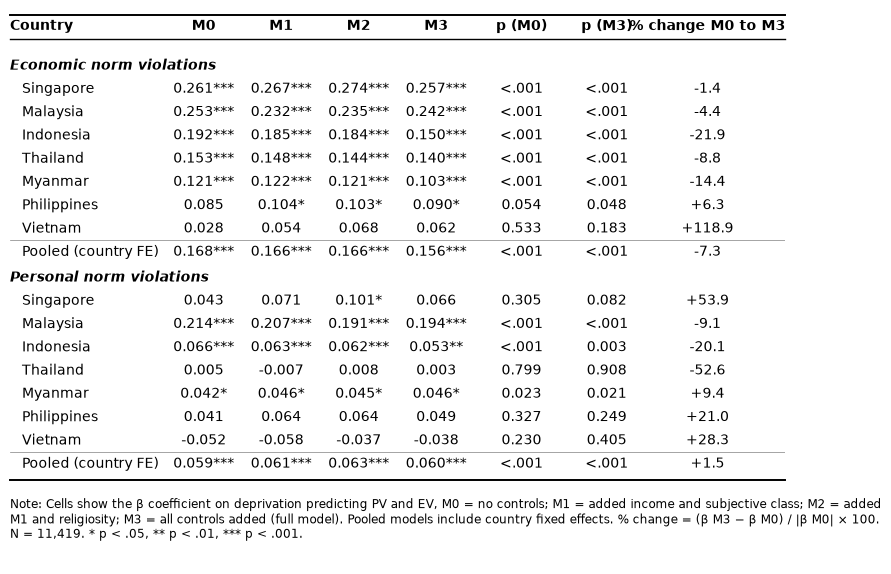

,Outcome,Country,M0,M1,M2,M3,p (M0),p (M3),% change M0 to M3
0,Economic,Singapore,0.261***,0.267***,0.274***,0.257***,<.001,<.001,-1.4
1,Economic,Malaysia,0.253***,0.232***,0.235***,0.242***,<.001,<.001,-4.4
2,Economic,Indonesia,0.192***,0.185***,0.184***,0.150***,<.001,<.001,-21.9
3,Economic,Thailand,0.153***,0.148***,0.144***,0.140***,<.001,<.001,-8.8
4,Economic,Myanmar,0.121***,0.122***,0.121***,0.103***,<.001,<.001,-14.4
5,Economic,Philippines,0.085,0.104*,0.103*,0.090*,0.054,0.048,+6.3
6,Economic,Vietnam,0.028,0.054,0.068,0.062,0.533,0.183,+118.9
7,Economic,Pooled (country FE),0.168***,0.166***,0.166***,0.156***,<.001,<.001,-7.3
8,Personal,Singapore,0.043,0.071,0.101*,0.066,0.305,0.082,+53.9
9,Personal,Malaysia,0.214***,0.207***,0.191***,0.194***,<.001,<.001,-9.1


In [ ]:
# table to show the difference with control and without
import matplotlib.pyplot as plt

country_names = {'SGP': 'Singapore', 'MYS': 'Malaysia', 'IDN': 'Indonesia', 'THA': 'Thailand',
                 'MMR': 'Myanmar', 'PHL': 'Philippines', 'VNM': 'Vietnam', 'Pooled': 'Pooled (country FE)'}
row_order = ['SGP', 'MYS', 'IDN', 'THA', 'MMR', 'PHL', 'VNM', 'Pooled']
steps = ['M0', 'M1', 'M2', 'M3']

def stars(p):
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''

def fmt_p(p):
    return '<.001' if p < .001 else f'{p:.3f}'

rows = []
for outcome in ['Economic', 'Personal']:
    for c in row_order:
        r = seq[(seq['outcome'] == outcome) & (seq['country'] == c)].set_index('model')
        b0, b3 = r.loc['M0', 'beta'], r.loc['M3', 'beta']
        row = {'Outcome': outcome, 'Country': country_names[c]}
        for s in steps:
            row[s] = f"{r.loc[s, 'beta']:.3f}{stars(r.loc[s, 'p'])}"
        row['p (M0)'] = fmt_p(r.loc['M0', 'p'])
        row['p (M3)'] = fmt_p(r.loc['M3', 'p'])
        row['% change M0 to M3'] = f"{100 * (b3 - b0) / abs(b0):+.1f}"
        rows.append(row)

beta_table = pd.DataFrame(rows)
beta_table.to_csv('../output/tables/deprivation_beta_by_model.csv', index=False)

# Draw the table as a figure for the paper
cols = ['Country'] + steps + ['p (M0)', 'p (M3)', '% change M0 to M3']
fig, ax = plt.subplots(figsize=(10, 7.2))
ax.axis('off')

y, line_h = 0.97, 0.042
xs = [0.0, 0.25, 0.35, 0.45, 0.55, 0.66, 0.77, 0.90]   # column positions
aligns = ['left'] + ['center'] * 7

def hline(y, lw=1.0):
    ax.plot([0, 1], [y, y], color='black', lw=lw, transform=ax.transAxes, clip_on=False)

hline(y + 0.02, 1.4)
for x, col, a in zip(xs, cols, aligns):
    ax.text(x, y, col, ha=a, va='center', fontweight='bold', fontsize=10, transform=ax.transAxes)
y -= line_h * 0.8
hline(y + 0.01)

for outcome in ['Economic', 'Personal']:
    y -= line_h * 0.9
    ax.text(0, y, f'{outcome} norm violations', ha='left', va='center', fontstyle='italic',
            fontweight='bold', fontsize=10, transform=ax.transAxes)
    sub = beta_table[beta_table['Outcome'] == outcome]
    for _, r in sub.iterrows():
        y -= line_h
        if r['Country'].startswith('Pooled'):
            ax.plot([0, 1], [y + line_h / 2, y + line_h / 2], color='grey', lw=0.5,
                    transform=ax.transAxes)
        for x, col, a in zip(xs, cols, aligns):
            label = ('   ' + r[col]) if col == 'Country' else r[col]
            ax.text(x, y, label, ha=a, va='center', fontsize=10, transform=ax.transAxes)
    y -= line_h * 0.2
y -= line_h * 0.5
hline(y, 1.4)

note = ("Note: Cells show the β coefficient on deprivation predicting PV and EV, "
        "M0 = no controls; M1 = added income and subjective class; M2 = added M1 and religiosity; "
        "M3 = all controls added (full model). Pooled models include country fixed effects. "
        "% change = (β M3 − β M0) / |β M0| × 100. "
        "N = 11,419. * p < .05, ** p < .01, *** p < .001.")
ax.text(0, y - 0.03, note, ha='left', va='top', fontsize=8.5, wrap=True, transform=ax.transAxes)

plt.savefig('../output/figures/deprivation_beta_by_model.png', dpi=300, bbox_inches='tight')
plt.show()
beta_table

In [28]:
# R^2 for each model (pooled)
r2_table = seq[seq['country'] == ALL].pivot(index='outcome', columns='model', values='r2')
r2_table = r2_table.loc[['Economic', 'Personal']]
r2_table['Change M0 to full'] = r2_table[FULL] - r2_table['M0']
print('R² by model (pooled)')
print(r2_table.round(3).to_string())

# R^2 for the full model in each country
r2_country = seq[(seq['model'] == FULL) & (seq['outcome'] != 'Gap')].pivot(index='country', columns='outcome', values='r2')
print(f'\nR² for the full model ({FULL}) by country')
print(r2_country.round(3).to_string())

R² by model (pooled)
model        M0     M1     M2     M3  Change M0 to full
outcome                                                
Economic  0.231  0.231  0.231  0.239              0.008
Personal  0.231  0.232  0.253  0.259              0.027

R² for the full model (M3) by country
outcome  Economic  Personal
country                    
IDN         0.081     0.028
MMR         0.048     0.021
MYS         0.083     0.045
PHL         0.015     0.028
Pooled      0.239     0.259
SGP         0.083     0.263
THA         0.069     0.052
VNM         0.023     0.017


In [29]:
# Pooled model output with every control shown (economic, then personal)
# All seven country rows are listed in the next cell, because effect coding shows one fewer here
for label in ['Economic', 'Personal']:
    m = models[(ALL, label, FULL)]
    print(f"\n=== Pooled {label}, {FULL} with effect-coded country fixed effects ===")
    print(m.summary().tables[1])


=== Pooled Economic, M3 with effect-coded country fixed effects ===
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5.6339      0.225     25.094      0.000       5.194       6.074
C(country, Sum)[S.IDN]    -1.0124      0.076    -13.352      0.000      -1.161      -0.864
C(country, Sum)[S.MMR]    -0.9078      0.078    -11.710      0.000      -1.060      -0.756
C(country, Sum)[S.MYS]     1.6575      0.104     15.962      0.000       1.454       1.861
C(country, Sum)[S.PHL]     2.8792      0.125     22.979      0.000       2.634       3.125
C(country, Sum)[S.SGP]    -1.5476      0.070    -22.103      0.000      -1.685      -1.410
C(country, Sum)[S.THA]    -2.0275      0.081    -25.025      0.000      -2.186      -1.869
deprivation_rebased20      0.1560      0.012     13.168      0.000       0.133       0.179
income               

# Comparing each country to the regional average 

After adjusting for all individual level covariation, we evaluate national baseline differences in moral permissiveness by calculating how much each country deviates from the overall seven country mean.

In [30]:
# comparing each country with the average of the region

def country_effects(m, levels):
    # Every country's deviation from the 7-country average, including the one effect coding leaves out
    names = list(m.params.index)
    shown = [n for n in names if n.startswith(COUNTRY_FE + '[S.')]
    rows = []
    for lv in levels:
        r = np.zeros(len(names))
        term = f'{COUNTRY_FE}[S.{lv}]'
        if term in names:
            r[names.index(term)] = 1
        else:                                   # omitted country = -(sum of the others)
            for n in shown:
                r[names.index(n)] = -1
        t = m.t_test(r)
        lo, hi = np.asarray(t.conf_int()).ravel()
        rows.append({'country': country_names[lv], 'effect': float(np.squeeze(t.effect)), 'ci_low': lo, 'ci_high': hi,
                     'p': float(np.squeeze(t.pvalue))})
    return pd.DataFrame(rows)

def stars(p):
    if p < .001:
        return '***'
    elif p < .01:
        return '**'
    elif p < .05:
        return '*'
    return ''

levels = sorted(analysis['country'].unique())
ce = pd.concat([country_effects(models[(ALL, label, FULL)], levels).assign(outcome=label) for label in ['Economic', 'Personal']])
ce.to_csv('../output/tables/ols_controls_country_effects.csv', index=False)
ce['effect [95% CI]'] = ce.apply(lambda r: f"{r.effect:+.2f}{stars(r.p)} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]", axis=1)
print('Country effects: difference from the seven-country average (justifiability score, 2-20)')
print(ce.pivot(index='country', columns='outcome', values='effect [95% CI]').to_string())
print('\nCheck: effects sum to zero ->', ce.groupby('outcome')['effect'].sum().round(10).to_dict())
print('* p < .05, ** p < .01, *** p < .001')

Country effects: difference from the seven-country average (justifiability score, 2-20)
outcome                     Economic                 Personal
country                                                      
Indonesia    -1.01*** [-1.16, -0.86]  -1.97*** [-2.10, -1.83]
Malaysia     +1.66*** [+1.45, +1.86]  +1.31*** [+1.11, +1.51]
Myanmar      -0.91*** [-1.06, -0.76]  -1.75*** [-1.87, -1.63]
Philippines  +2.88*** [+2.63, +3.12]  +1.77*** [+1.53, +2.00]
Singapore    -1.55*** [-1.68, -1.41]  -0.29*** [-0.44, -0.15]
Thailand     -2.03*** [-2.19, -1.87]  -0.75*** [-0.91, -0.59]
Vietnam      +0.96*** [+0.77, +1.15]  +1.68*** [+1.49, +1.86]

Check: effects sum to zero -> {'Economic': 0.0, 'Personal': 0.0}
* p < .05, ** p < .01, *** p < .001


# Robustness check

Because the internal consistency of the composite religiosity measure may vary across countries due to ceiling effects, we re-estimated the models using its three underlying items (religious importance, belief, and practice) as separate controls, both within each country and pooled. The estimated relationship between material deprivation and moral norms remains virtually unchanged, indicating that our results are robust to how religiosity is measured.

In [31]:
item_controls = [c for c in all_controls if c != 'religiosity'] + rel_items
rel_data = analysis.dropna(subset=rel_items)
rel_rows = []
for label in ['Economic', 'Personal']:
    for country, data in [(c, g) for c, g in rel_data.groupby('country')] + [(ALL, rel_data)]:
        fe = country == ALL
        a = fit_wls(DVS[label], all_controls, data, fe)
        b = fit_wls(DVS[label], item_controls, data, fe)
        rel_rows.append({'outcome': label, 'country': country, 'β (index)': a.params[IV], 'p (index)': a.pvalues[IV],
                         'β (3 items)': b.params[IV], 'p (3 items)': b.pvalues[IV]})
print(pd.DataFrame(rel_rows).set_index(['outcome', 'country']).round(3).to_string())

                  β (index)  p (index)  β (3 items)  p (3 items)
outcome  country                                                
Economic IDN          0.154      0.000        0.152        0.000
         MMR          0.103      0.000        0.102        0.000
         MYS          0.242      0.000        0.244        0.000
         PHL          0.090      0.048        0.093        0.043
         SGP          0.253      0.000        0.255        0.000
         THA          0.138      0.000        0.129        0.000
         VNM          0.062      0.183        0.060        0.198
         Pooled       0.157      0.000        0.156        0.000
Personal IDN          0.055      0.002        0.050        0.004
         MMR          0.046      0.021        0.046        0.023
         MYS          0.194      0.000        0.189        0.000
         PHL          0.049      0.249        0.050        0.242
         SGP          0.057      0.142        0.067        0.083
         THA         -0.0

# Robustness check: rank-transformed outcome 

To test whether our findings are sensitive to the right-skewed distribution or interval-scale assumptions of the survey items, we converted the economic and personal norm violation scores into within-country percentile ranks (0–100) and re-estimated the models. The coefficients show the same pattern: deprivation remains more strongly associated with economic than with personal norm violations, indicating that the skewness of the distribution does not affect our results.

In [32]:
# Rank-transform the outcomes within each country, to address concerns about the
# skewed distribution of the 1-10 scale and its equal-interval assumption
analysis['EV_rank'] = analysis.groupby('country')['EV_rebased20'].rank(pct=True) * 100
analysis['PV_rank'] = analysis.groupby('country')['PV_rebased20'].rank(pct=True) * 100

DVS_rank = {'Economic (rank)': 'EV_rank', 'Personal (rank)': 'PV_rank'}

rank_rows = []
for dv_label, dv in DVS_rank.items():
    groups = [(c, g) for c, g in analysis.groupby('country')] + [(ALL, analysis)]
    for country, data in groups:
        m = fit_wls(dv, all_controls, data, country_effects=(country == ALL))
        lo, hi = m.conf_int().loc[IV]
        rank_rows.append({'country': country, 'outcome': dv_label, 'beta': m.params[IV],
                           'se': m.bse[IV], 'ci_low': lo, 'ci_high': hi, 'p': m.pvalues[IV],
                           'n': int(m.nobs), 'r2': m.rsquared})

rank_table = pd.DataFrame(rank_rows)
rank_table.to_csv('../output/tables/ols_rank_robustness.csv', index=False)
print('Beta on deprivation, rank-transformed outcome (full controls)')
print(rank_table.round(3).to_string())

Beta on deprivation, rank-transformed outcome (full controls)
   country          outcome   beta     se  ci_low  ci_high      p      n     r2
0      IDN  Economic (rank)  1.265  0.223   0.827    1.702  0.000   3127  0.077
1      MMR  Economic (rank)  1.010  0.291   0.440    1.581  0.001   1198  0.040
2      MYS  Economic (rank)  1.819  0.226   1.376    2.261  0.000   1313  0.093
3      PHL  Economic (rank)  0.736  0.322   0.104    1.368  0.022   1199  0.015
4      SGP  Economic (rank)  2.701  0.362   1.991    3.412  0.000   1925  0.092
5      THA  Economic (rank)  2.163  0.180   1.809    2.516  0.000   1457  0.122
6      VNM  Economic (rank)  0.588  0.413  -0.222    1.398  0.155   1200  0.028
7   Pooled  Economic (rank)  1.581  0.100   1.384    1.778  0.000  11419  0.045
8      IDN  Personal (rank)  0.818  0.231   0.365    1.270  0.000   3127  0.024
9      MMR  Personal (rank)  0.756  0.289   0.190    1.322  0.009   1198  0.027
10     MYS  Personal (rank)  1.436  0.234   0.977    1.895

# Robustness check for the personal values

We conduct a robustness check to test the construction of 'personal value' as a variable. This is because the survey questions that made up personal values was very varied. We constructed an alternative, narrower eight-item index that excludes items on domestic violence, child abuse, political violence, terrorism, interpersonal violence, and the death penalty. The result shows that the gap between economic and personal norms remains positive and significant, and even widening in several countries. This indicates that our main finding is not driven by violence-related items. However, the deprivation coefficient on personal norms itself is somewhat sensitive to this change (pooled: 0.060 to 0.038), so personal-norm results should be interpreted carefully. 


In [ ]:
#narrow down the questions to exclude questions regarding violence and death penalty 
narrow_items_pv = ['Q182', 'Q183', 'Q184', 'Q185', 'Q186', 'Q187', 'Q188', 'Q193']

# rebase the responses to 20 (2-20)
analysis['PV_narrow_rebased20'] = analysis[narrow_items_pv].mean(axis=1) * 2
analysis['gap_EV_PV_narrow'] = analysis['EV_rebased20'] - analysis['PV_narrow_rebased20']

DVS_narrow = {'Personal (14 items, main)': 'PV_rebased20',
              'Personal (8 items, narrow)': 'PV_narrow_rebased20',
              'Gap (14 items, main)': 'gap_EV_PV',
              'Gap (8 items, narrow)': 'gap_EV_PV_narrow'}

narrow_rows = []
for dv_label, dv in DVS_narrow.items():
    groups = [(c, g) for c, g in analysis.groupby('country')] + [(ALL, analysis)]
    for country, data in groups:
        m = fit_wls(dv, all_controls, data, country_effects=(country == ALL))
        lo, hi = m.conf_int().loc[IV]
        narrow_rows.append({'country': country, 'outcome': dv_label, 'beta': m.params[IV],
                            'se': m.bse[IV], 'ci_low': lo, 'ci_high': hi, 'p': m.pvalues[IV],
                            'n': int(m.nobs)})

narrow_table = pd.DataFrame(narrow_rows)
narrow_table.to_csv('../output/tables/robustness_narrow_personal_index.csv', index=False)

# Create a comparision table for smaller vs larger personal norm variable 
narrow_table['β'] = narrow_table.apply(lambda r: f"{r.beta:.3f}{stars(r.p)}", axis=1)
print('Beta on deprivation, full model (M3): main 14-item vs narrow 8-item personal index')
print(narrow_table.pivot(index='country', columns='outcome', values='β')[list(DVS_narrow)].to_string())
print('\n* p < .05, ** p < .01, *** p < .001')

Beta on deprivation, full model (M3): main 14-item vs narrow 8-item personal index
outcome Personal (14 items, main) Personal (8 items, narrow) Gap (14 items, main) Gap (8 items, narrow)
country                                                                                                
IDN                       0.053**                    0.054**             0.097***              0.096***
MMR                        0.046*                      0.028               0.057*               0.075**
MYS                      0.194***                   0.185***                0.047                0.057*
PHL                         0.049                      0.048                0.041                 0.042
Pooled                   0.060***                    0.038**             0.096***              0.118***
SGP                         0.066                      0.043             0.192***              0.214***
THA                         0.003                  -0.087***             0.137***    

# Forest Plot 
The results are summarised in forest plots showing point estimates and 95% confidence intervals for the deprivation coefficient across the seven countries and the pooled sample. A two-panel plot contrasts economic and personal norms under both the unadjusted baseline and the fully controlled models. A second plot shows the gap outcome (economic minus personal). The gap is positive in every country, and the pooled estimate lies significantly to the right of zero, indicating that deprivation is more strongly associated with economic than with personal norm violations.

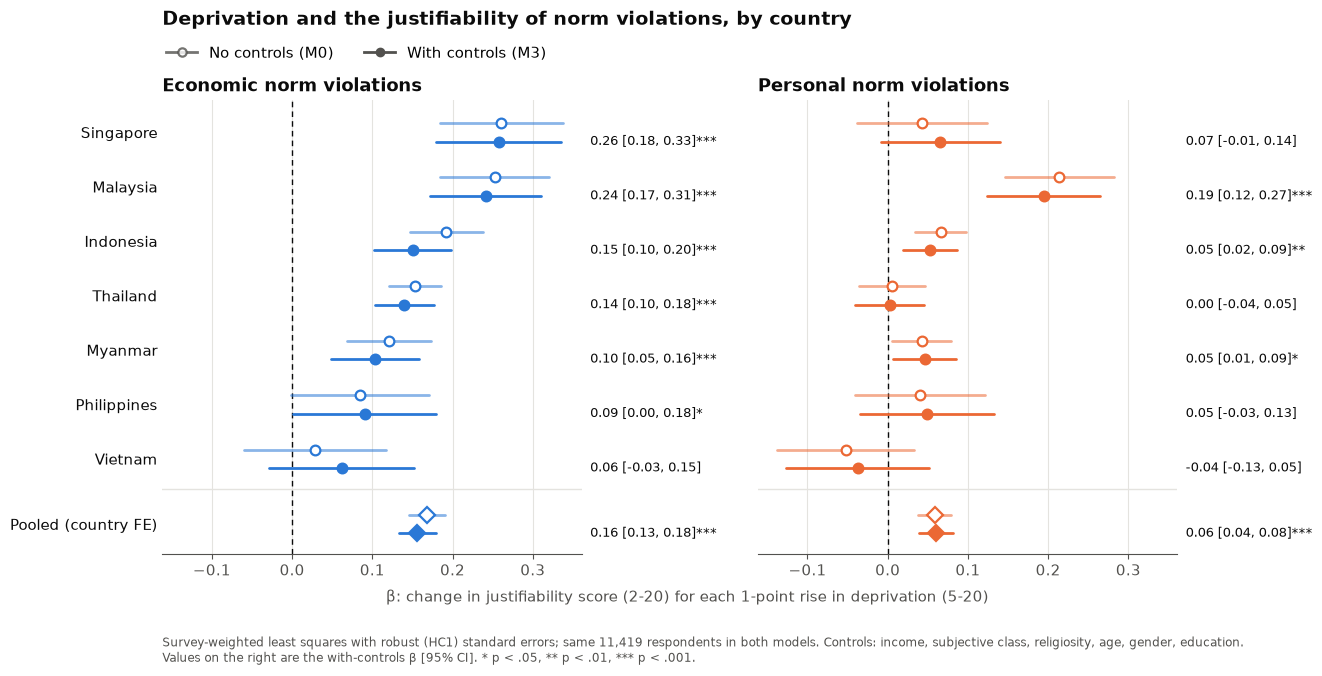

In [34]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.edgecolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': INK, 'axes.labelcolor': MUTED})
FIG = '../output/figures/'
get = lambda country, outcome, step: seq[(seq.country == country) & (seq.outcome == outcome) & (seq.model == step)].iloc[0]

# Rows ordered by the adjusted economic β, pooled estimate at the bottom
row_order = (seq[(seq.outcome == 'Economic') & (seq.model == FULL) & (seq.country != ALL)]
             .sort_values('beta', ascending=False)['country'].tolist())
row_y = {c: len(row_order) - i for i, c in enumerate(row_order)}
row_y[ALL] = -0.2
row_names = {**country_names, ALL: 'Pooled (country FE)'}


def forest_panel(ax, outcome, color, offset=0.17):
    for country, y in row_y.items():
        pooled = country == ALL
        for step, dy, face in [('M0', offset, 'white'), (FULL, -offset, color)]:
            r = get(country, outcome, step)
            ax.plot([r.ci_low, r.ci_high], [y + dy] * 2, color=color, lw=2,
                    alpha=0.55 if step == 'M0' else 1, solid_capstyle='round', zorder=2)
            ax.plot(r.beta, y + dy, marker='D' if pooled else 'o', ms=8 if pooled else 7, mfc=face,
                    mec=color, mew=1.6, ls='none', zorder=3)
        a = get(country, outcome, FULL)
        ax.text(1.02, y - offset, f'{a.beta:.2f} [{a.ci_low:.2f}, {a.ci_high:.2f}]{stars(a.p)}',
                transform=ax.get_yaxis_transform(), va='center', fontsize=9.5, color=INK)
    ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)), zorder=1)
    ax.axhline(0.45, color=GRID, lw=1)
    ax.grid(axis='x', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_yticks(list(row_y.values()), [row_names[c] for c in row_y])
    ax.tick_params(axis='y', length=0)
    ax.set_ylim(-0.75, len(row_order) + 0.6)


legend_handles = [
    Line2D([], [], marker='o', mfc='white', mec=MUTED, mew=1.6, color=MUTED, alpha=0.8, lw=2, label='No controls (M0)'),
    Line2D([], [], marker='o', mfc=MUTED, mec=MUTED, color=MUTED, lw=2, label=f'With controls ({FULL})'),
]
ctrl_note = 'income, subjective class, religiosity, age, gender, education'
footnote = (f'Survey-weighted least squares with robust (HC1) standard errors; same {len(analysis):,} respondents in both models. '
            f'Controls: {ctrl_note}.\nValues on the right are the with-controls β [95% CI]. '
            '* p < .05, ** p < .01, *** p < .001.')

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharex=True, sharey=True, gridspec_kw={'wspace': 0.42})
forest_panel(axes[0], 'Economic', BLUE)
forest_panel(axes[1], 'Personal', ORANGE)
axes[0].set_title('Economic norm violations', loc='left', fontweight='bold', color=INK)
axes[1].set_title('Personal norm violations', loc='left', fontweight='bold', color=INK)
fig.supxlabel('β: change in justifiability score (2-20) for each 1-point rise in deprivation (5-20)', color=MUTED, fontsize=11, y=0.07)
fig.suptitle('Deprivation and the justifiability of norm violations, by country', x=0.125, ha='left', fontsize=14, fontweight='bold', color=INK, y=1.0)
fig.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0.118, 0.965), ncol=2, frameon=False)
fig.text(0.125, -0.025, footnote, fontsize=8.5, color=MUTED, va='bottom')
fig.subplots_adjust(top=0.86, bottom=0.15, right=0.85)
plt.savefig(FIG + 'forest_deprivation_by_country.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

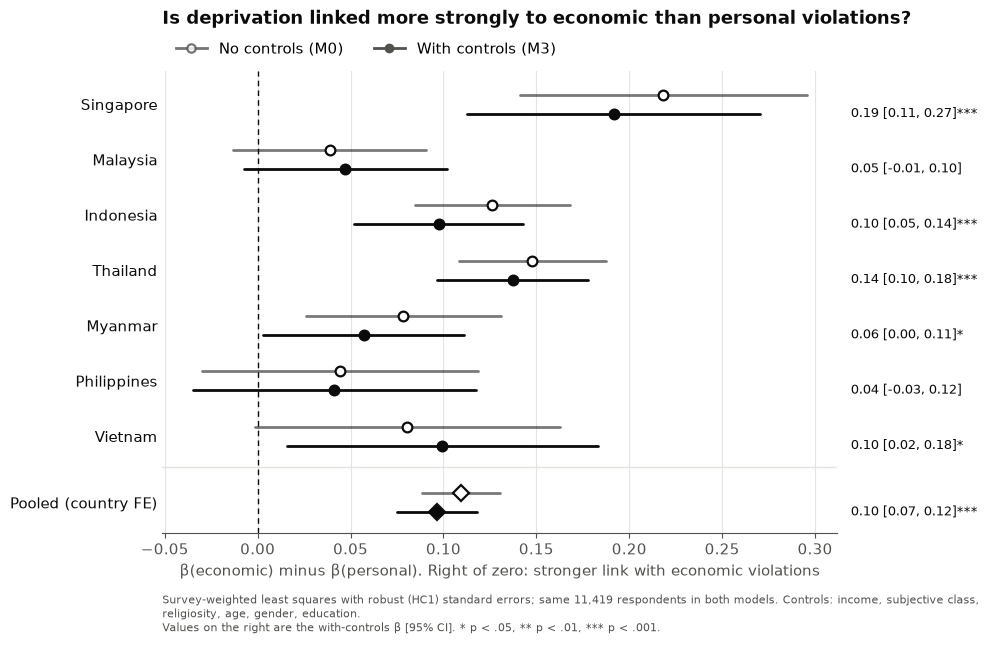

In [35]:
# Forest plot for the research question: economic minus personal
# Right of zero = deprivation is linked more strongly to economic than to personal violations
fig, ax = plt.subplots(figsize=(10, 6))
forest_panel(ax, 'Gap', INK)
ax.set_title('Is deprivation linked more strongly to economic than personal violations?', loc='left', fontweight='bold', color=INK, pad=34)
ax.set_xlabel('β(economic) minus β(personal). Right of zero: stronger link with economic violations')
ax.legend(handles=legend_handles, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
fig.text(0.125, -0.06, footnote, fontsize=8, color=MUTED, va='bottom', wrap=True)
fig.subplots_adjust(right=0.8)
plt.savefig(FIG + 'forest_economic_minus_personal.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

# Accounting for controls
Lastly, to compare the strength of predictors, all continuous variables were standardised into z-scores, so that each coefficient reflects the effect of a one standard deviation change in that predictor. The standardised coefficients are summarised in a table and an error-bar chart. We also plot model-adjusted regression lines for each country, showing predicted justifiability across deprivation while holding all six control variables at their country-specific weighted averages.

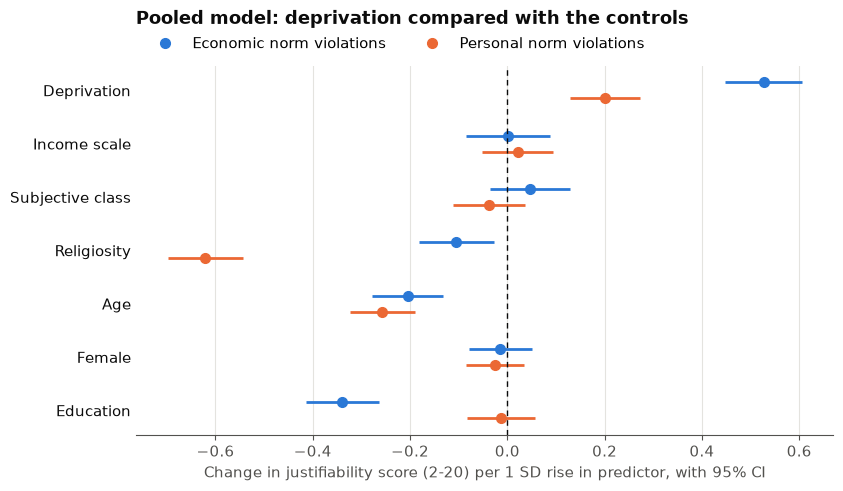

outcome           Economic  Personal
predictor                           
Age                 -0.205    -0.257
Deprivation          0.527     0.201
Education           -0.339    -0.013
Female              -0.015    -0.025
Income scale         0.001     0.021
Religiosity         -0.105    -0.621
Subjective class     0.047    -0.038


In [36]:
# beta coefficients for each of the variables, ceteris paribus 

z = analysis.copy()
predictors = [IV] + all_controls
z[predictors] = (z[predictors] - z[predictors].mean()) / z[predictors].std()
labels = {IV: 'Deprivation', 'income': 'Income scale', 'subj_class': 'Subjective class', 'religiosity': 'Religiosity',
          'age': 'Age', 'female': 'Female', 'education': 'Education'}

std_rows = []
for label, color, dy in [('Economic', BLUE, 0.15), ('Personal', ORANGE, -0.15)]:
    m = smf.wls(f"{DVS[label]} ~ {' + '.join(predictors)} + {COUNTRY_FE}", data=z, weights=z['W_WEIGHT']).fit(cov_type='HC1', use_t=True)
    ci = m.conf_int()
    for p in predictors:
        std_rows.append({'outcome': label, 'predictor': labels[p], 'beta_per_sd': m.params[p],
                         'ci_low': ci.loc[p, 0], 'ci_high': ci.loc[p, 1], 'p': m.pvalues[p]})
std_coef = pd.DataFrame(std_rows)
std_coef.to_csv('../output/tables/ols_controls_standardised_coefficients.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
ypos = {labels[p]: len(predictors) - i for i, p in enumerate(predictors)}
for label, color, dy in [('Economic', BLUE, 0.15), ('Personal', ORANGE, -0.15)]:
    d = std_coef[std_coef.outcome == label]
    y = d['predictor'].map(ypos) + dy
    ax.hlines(y, d['ci_low'], d['ci_high'], color=color, lw=2)
    ax.plot(d['beta_per_sd'], y, 'o', color=color, ms=7, label=f'{label} norm violations')
ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)))
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_yticks(list(ypos.values()), list(ypos))
ax.tick_params(axis='y', length=0)
ax.set_xlabel('Change in justifiability score (2-20) per 1 SD rise in predictor, with 95% CI')
ax.set_title('Pooled model: deprivation compared with the controls', loc='left', fontweight='bold', color=INK, pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
plt.savefig(FIG + 'pooled_standardised_coefficients.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(std_coef.pivot(index='predictor', columns='outcome', values='beta_per_sd').round(3).to_string())

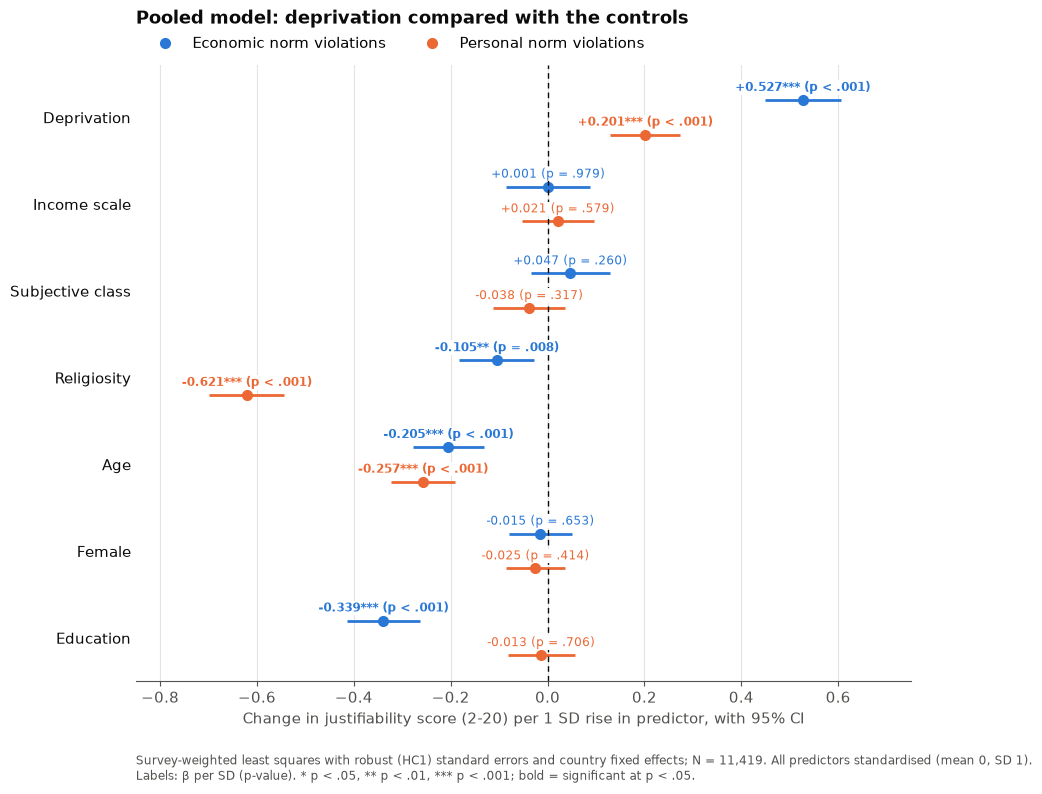

In [37]:
#forest plot with the beta values 

z = analysis.copy()
predictors = [IV] + all_controls
z[predictors] = (z[predictors] - z[predictors].mean()) / z[predictors].std()
labels = {IV: 'Deprivation', 'income': 'Income scale', 'subj_class': 'Subjective class', 'religiosity': 'Religiosity',
          'age': 'Age', 'female': 'Female', 'education': 'Education'}

std_rows = []
for label in ['Economic', 'Personal']:
    m = smf.wls(f"{DVS[label]} ~ {' + '.join(predictors)} + {COUNTRY_FE}", data=z, weights=z['W_WEIGHT']).fit(cov_type='HC1', use_t=True)
    ci = m.conf_int()
    for p in predictors:
        std_rows.append({'outcome': label, 'predictor': labels[p], 'beta_per_sd': m.params[p],
                         'ci_low': ci.loc[p, 0], 'ci_high': ci.loc[p, 1], 'p': m.pvalues[p]})
std_coef = pd.DataFrame(std_rows)
std_coef.to_csv('../output/tables/ols_controls_standardised_coefficients.csv', index=False)


def fmt_p(p):
    return 'p < .001' if p < .001 else f'p = {p:.3f}'.replace('0.', '.')

fig, ax = plt.subplots(figsize=(10, 8))
ypos = {labels[p]: len(predictors) - i for i, p in enumerate(predictors)}
series = [('Economic', BLUE, 0.2), ('Personal', ORANGE, -0.2)]

for label, color, dy in series:
    d = std_coef[std_coef.outcome == label]
    y = d['predictor'].map(ypos) + dy
    ax.hlines(y, d['ci_low'], d['ci_high'], color=color, lw=2)
    ax.plot(d['beta_per_sd'], y, 'o', color=color, ms=7, label=f'{label} norm violations')
    for _, r in d.iterrows():
        ax.text(r.beta_per_sd, ypos[r.predictor] + dy + 0.07,
                f'{r.beta_per_sd:+.3f}{stars(r.p)} ({fmt_p(r.p)})',
                ha='center', va='bottom', fontsize=8.5, color=color,
                fontweight='bold' if r.p < .05 else 'normal',
                bbox=dict(facecolor='white', edgecolor='none', pad=0.5), zorder=4)

ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)))
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_yticks(list(ypos.values()), list(ypos))
ax.tick_params(axis='y', length=0)
ax.set_ylim(0.5, len(predictors) + 0.6)
ax.set_xlim(-0.85, 0.75)   
ax.set_xlabel('Change in justifiability score (2-20) per 1 SD rise in predictor, with 95% CI')
ax.set_title('Pooled model: deprivation compared with the controls', loc='left', fontweight='bold', color=INK, pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
fig.text(0.125, 0.02,
         f'Survey-weighted least squares with robust (HC1) standard errors and country fixed effects; N = {len(z):,}. '
         'All predictors standardised (mean 0, SD 1).\nLabels: β per SD (p-value). * p < .05, ** p < .01, *** p < .001; bold = significant at p < .05.',
         fontsize=8.5, color=MUTED, va='top')
plt.savefig(FIG + 'pooled_standardised_coefficients.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

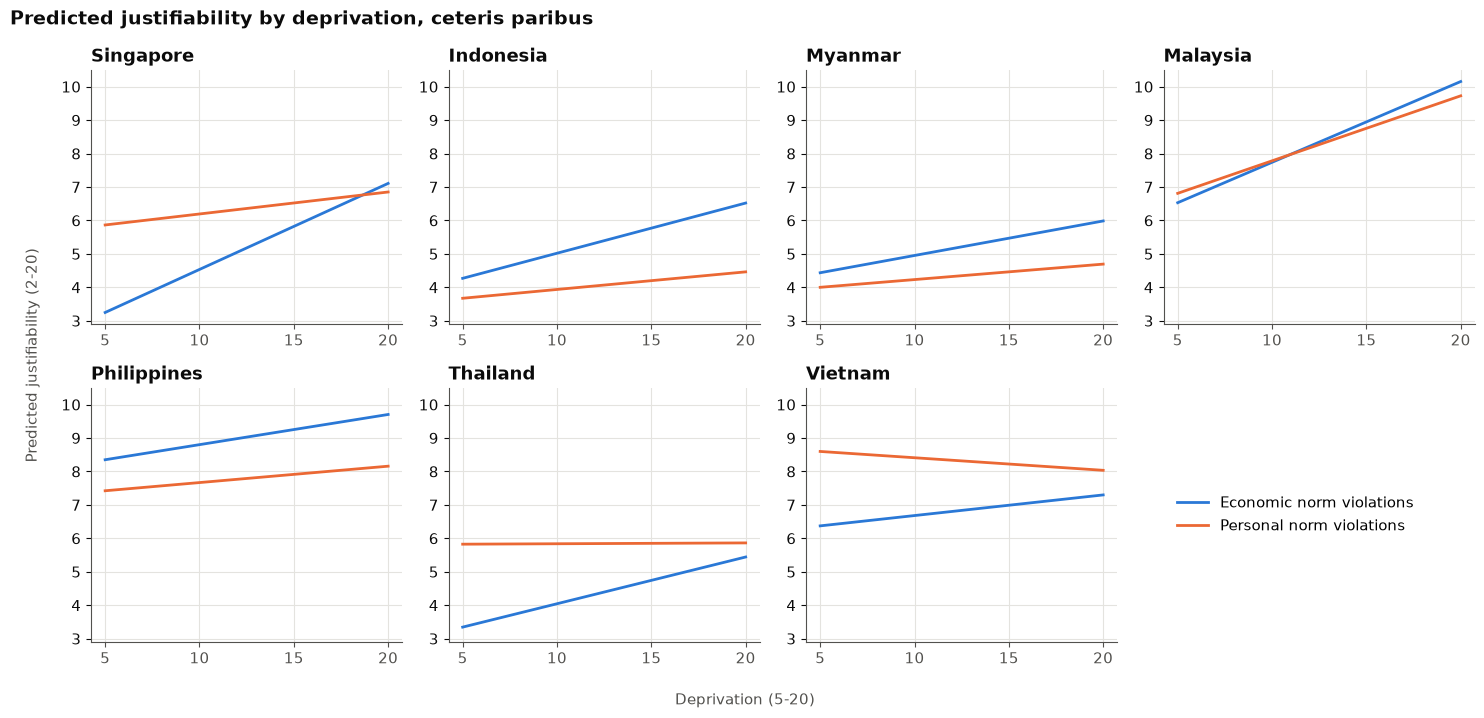

In [38]:
#Beta for economic and personal norms by country  

grid = np.linspace(5, 20, 50)
panel_order = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True, sharey=True)
axes = axes.ravel()

for ax, c in zip(axes, panel_order):
    data = analysis[analysis['country'] == c]
    held = {v: np.average(data[v], weights=data['W_WEIGHT']) for v in all_controls}
    new_x = pd.DataFrame({IV: grid, **held})
    for label, color in [('Economic', BLUE), ('Personal', ORANGE)]:
        pred = models[(c, label, FULL)].get_prediction(new_x, weights=1).summary_frame(alpha=0.05)
        ax.plot(grid, pred['mean'], color=color, lw=2)
    ax.set_title(country_names[c], loc='left', fontweight='bold', color=INK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines['left'].set_visible(True)
    ax.tick_params(labelbottom=True, labelleft=True)

axes[-1].axis('off')
axes[-1].legend(handles=[Line2D([], [], color=BLUE, lw=2, label='Economic norm violations'),
                         Line2D([], [], color=ORANGE, lw=2, label='Personal norm violations')],
                loc='center left', frameon=False)

fig.supxlabel('Deprivation (5-20)', color=MUTED, fontsize=11)
fig.supylabel('Predicted justifiability (2-20)', color=MUTED, fontsize=11)
fig.suptitle("Predicted justifiability by deprivation, ceteris paribus",
             x=0.01, ha='left', fontsize=14, fontweight='bold', color=INK)
fig.tight_layout(rect=(0.012, 0, 1, 1))
plt.savefig(FIG + 'adjusted_regression_lines_by_country.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()